In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

from pathlib import Path
from sklearn.model_selection import train_test_split

warnings.filterwarnings("ignore")

RANDOM_STATE = 42

In [2]:
train_df = pd.read_csv(
    "../data/processed/cleaned_training_data.csv"
)

test_df = pd.read_csv(
    "../data/raw/UNSW_NB15_testing-set.csv"
)

print("Datasets loaded successfully!")

print("Training Shape:", train_df.shape)
print("Testing Shape:", test_df.shape)

Datasets loaded successfully!
Training Shape: (175341, 43)
Testing Shape: (82332, 45)


In [3]:
test_df = test_df.drop(
    columns=["id", "attack_cat"],
    errors="ignore"
)

test_df = test_df.replace(
    [np.inf, -np.inf], np.nan
)

print("Cleaned Testing Shape:", test_df.shape)

Cleaned Testing Shape: (82332, 43)


In [4]:
X = train_df.drop(columns=["label"])
y = train_df["label"]

X_test = test_df.drop(columns=["label"])
y_test = test_df["label"]

print("Training Features:", X.shape)
print("Training Target:", y.shape)

print("\nTesting Features:", X_test.shape)
print("Testing Target:", y_test.shape)

Training Features: (175341, 42)
Training Target: (175341,)

Testing Features: (82332, 42)
Testing Target: (82332,)


In [5]:
assert set(X.columns) == set(X_test.columns), \
    "Feature columns do not match!"

X_test = X_test[X.columns]

assert X.columns.equals(X_test.columns)

print("All feature columns match successfully!")
print("Total Input Features:", X.shape[1])

All feature columns match successfully!
Total Input Features: 42


In [6]:
X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training Features:", X_train.shape)
print("Training Target:", y_train.shape)

print("\nValidation Features:", X_val.shape)
print("Validation Target:", y_val.shape)

print("\nTesting Features:", X_test.shape)
print("Testing Target:", y_test.shape)

Training Features: (140272, 42)
Training Target: (140272,)

Validation Features: (35069, 42)
Validation Target: (35069,)

Testing Features: (82332, 42)
Testing Target: (82332,)


In [7]:
distribution = pd.DataFrame({
    "Training": y_train.value_counts(),
    "Validation": y_val.value_counts(),
    "Testing": y_test.value_counts()
})

distribution = distribution.rename(
    index={0: "Normal", 1: "Malicious"}
)

display(distribution)

,Training,Validation,Testing
label,,,
Malicious,95472,23869,45332
Normal,44800,11200,37000


In [8]:
percentage_distribution = pd.DataFrame({
    "Training": y_train.value_counts(normalize=True) * 100,
    "Validation": y_val.value_counts(normalize=True) * 100,
    "Testing": y_test.value_counts(normalize=True) * 100
})

percentage_distribution = percentage_distribution.rename(
    index={0: "Normal", 1: "Malicious"}
)

display(percentage_distribution.round(2))

,Training,Validation,Testing
label,,,
Malicious,68.06,68.06,55.06
Normal,31.94,31.94,44.94


In [10]:
train_hash = pd.util.hash_pandas_object(
    X_train, index=False
)

val_hash = pd.util.hash_pandas_object(
    X_val, index=False
)

overlap = val_hash.isin(train_hash).sum()

print("Overlapping Validation Records:", overlap)

from sklearn.model_selection import StratifiedGroupKFold

if overlap > 0:

    groups = pd.util.hash_pandas_object(
        X, index=False
    )

    splitter = StratifiedGroupKFold(
        n_splits=5,
        shuffle=True,
        random_state=42
    )

    train_idx, val_idx = next(
        splitter.split(X, y, groups)
    )

    X_train = X.iloc[train_idx]
    X_val = X.iloc[val_idx]

    y_train = y.iloc[train_idx]
    y_val = y.iloc[val_idx]

    print("Group-aware splitting completed!")

else:
    print("No overlapping validation records found.")

Overlapping Validation Records: 16342
Group-aware splitting completed!


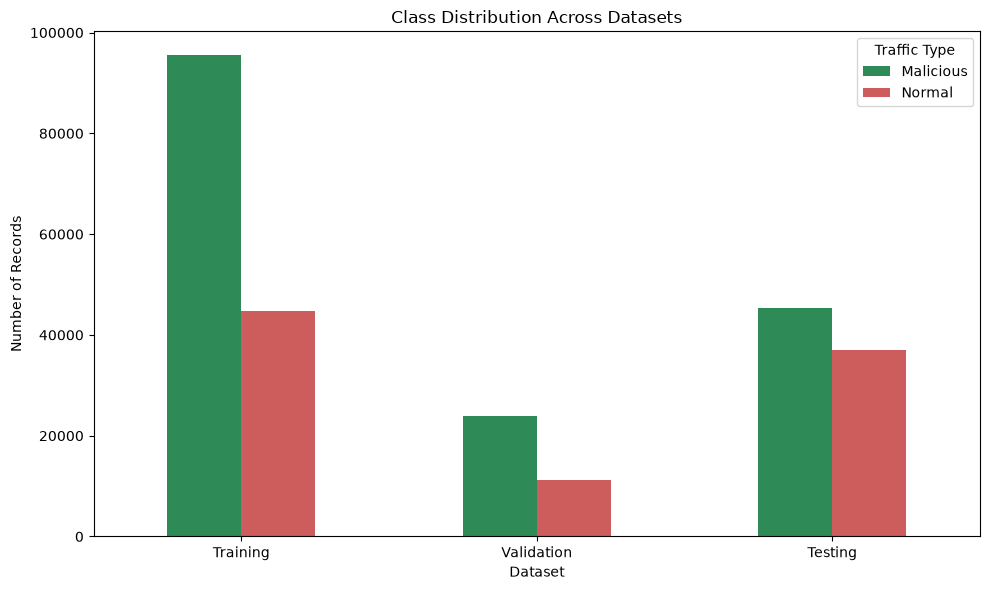

In [12]:
FIGURE_DIR = Path("../reports/figures")
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

distribution = pd.DataFrame({
    "Training": y_train.value_counts(),
    "Validation": y_val.value_counts(),
    "Testing": y_test.value_counts()
}).rename(index={0: "Normal", 1: "Malicious"})

distribution.T.plot(
    kind="bar",
    figsize=(10, 6),
    color=["seagreen", "indianred"]
)

plt.title("Class Distribution Across Datasets")
plt.xlabel("Dataset")
plt.ylabel("Number of Records")
plt.xticks(rotation=0)
plt.legend(title="Traffic Type")

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "dataset_split_distribution.png",
    dpi=300
)

plt.show()

In [13]:
PROCESSED_DIR = Path("../data/processed")
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

X_train.to_csv(
    PROCESSED_DIR / "X_train.csv", index=False
)

X_val.to_csv(
    PROCESSED_DIR / "X_val.csv", index=False
)

X_test.to_csv(
    PROCESSED_DIR / "X_test.csv", index=False
)

y_train.to_csv(
    PROCESSED_DIR / "y_train.csv", index=False
)

y_val.to_csv(
    PROCESSED_DIR / "y_val.csv", index=False
)

y_test.to_csv(
    PROCESSED_DIR / "y_test.csv", index=False
)

print("All datasets saved successfully!")

All datasets saved successfully!


In [14]:
RESULT_DIR = Path("../reports/results")
RESULT_DIR.mkdir(parents=True, exist_ok=True)

split_summary = pd.DataFrame({
    "Dataset": ["Training", "Validation", "Testing"],
    "Records": [
        len(X_train),
        len(X_val),
        len(X_test)
    ],
    "Features": [
        X_train.shape[1],
        X_val.shape[1],
        X_test.shape[1]
    ],
    "Normal": [
        (y_train == 0).sum(),
        (y_val == 0).sum(),
        (y_test == 0).sum()
    ],
    "Malicious": [
        (y_train == 1).sum(),
        (y_val == 1).sum(),
        (y_test == 1).sum()
    ]
})

display(split_summary)

split_summary.to_csv(
    RESULT_DIR / "dataset_split_summary.csv",
    index=False
)

print("Dataset split summary saved!")

,Dataset,Records,Features,Normal,Malicious
0,Training,140274,42,44800,95474
1,Validation,35067,42,11200,23867
2,Testing,82332,42,37000,45332


Dataset split summary saved!
